In [93]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_metadata.csv
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/hmnist_28_28_L.csv
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/hmnist_28_28_RGB.csv
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/hmnist_8_8_L.csv
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/hmnist_8_8_RGB.csv
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0024306.jpg
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0024307.jpg
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0024308.jpg
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0024309.jpg
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0024310.jpg
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0024311.jpg
/kaggle/input/datasets/kmader/skin-

In [94]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.endswith(".pt"):
            print("Model found:", os.path.join(root, file))

Model found: /kaggle/input/datasets/fatimaakhtar123/week6-model/week6_model.pt


In [95]:
import torch

model_path = "/kaggle/input/datasets/fatimaakhtar123/week6-model/week6_model.pt"

checkpoint = torch.load(
    model_path,
    map_location="cpu",
    weights_only=False
)

print("Backbone:", checkpoint["backbone"])
print("Image size:", checkpoint["img_size"])
print("Grayscale:", checkpoint["grayscale"])
print("Classes:", checkpoint["classes"])

Backbone: resnet18
Image size: 224
Grayscale: False
Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']


## Domain-Specific Sentences for NER

**Domain:** Healthcare and Medical AI (Medical Imaging and Dermatology)

The following 10 synthetic sentences are related to medical imaging, dermatology, skin-lesion classification, and artificial intelligence in healthcare. They contain people, organizations, locations, dates, quantities, and monetary amounts for Named Entity Recognition (NER) annotation in Part 3.

1. Dr. Ayesha Khan presented her skin cancer research at Aga Khan University in Karachi on 12 August 2026.
2. The dermatologist examined a patient with melanoma at Shaukat Khanum Hospital in Lahore.
3. Ali Hassan received a dermatology appointment on 15 September 2026.
4. The AI system analyzed 500 dermoscopic images to identify skin lesions.
5. Dr. Sara Ahmed developed a machine learning model for melanoma classification.
6. The hospital purchased a digital dermatoscope for Rs. 250,000.
7. The research team trained a ResNet18 model using the HAM10000 dataset on 20 October 2026.
8. A patient was diagnosed with basal cell carcinoma after a skin biopsy.
9. The medical imaging laboratory collected 1,200 skin lesion images for AI research.
10. The hospital allocated Rs. 500,000 for a new medical imaging system on 28 October 2026.

**Entity categories to annotate:**

- PERSON – Names of people
- ORG – Organizations and institutions
- GPE – Cities and geographical locations
- DATE – Dates
- MONEY – Monetary amounts
- CARDINAL – Numerical quantities

## Part 1: TF-IDF by Hand

### Objective
To manually reproduce TF-IDF calculations and verify them against the results generated by Scikit-learn.

### 1.1 TF-IDF Calculation Using Scikit-learn and Manual Verification

This section calculates TF-IDF scores for three sample documents using `TfidfVectorizer`. It then manually calculates the IDF values for the first document using the smooth IDF formula and applies L2 normalization.

The manually calculated results are compared with Scikit-learn to verify their accuracy.

In [96]:

import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

# Load spaCy English model
nlp = spacy.load('en_core_web_sm')

print('spaCy', spacy.__version__)

# Three sample documents
docs = [
    'win free cash now',
    'call me now',
    'free call now'
]

# Calculate TF-IDF using scikit-learn
vec = TfidfVectorizer()  # Smooth IDF + L2 normalization
X = vec.fit_transform(docs)

# Display TF-IDF values
print(
    pd.DataFrame(
        X.toarray(),
        columns=vec.get_feature_names_out(),
        index=['d1', 'd2', 'd3']
    ).round(3)
)

# Reproduce D1 manually
# IDF = ln((1 + N) / (1 + df)) + 1

N = 3

idf = {
    'win': np.log(4 / 2) + 1,
    'free': np.log(4 / 3) + 1,
    'cash': np.log(4 / 2) + 1,
    'now': np.log(4 / 4) + 1
}

# TF = 1 for each word in D1
v = np.array(list(idf.values()))

# Apply L2 normalization
normalized_v = v / np.linalg.norm(v)

print({
    w: round(x, 3)
    for w, x in zip(idf, normalized_v)
})


spaCy 3.8.16
     call   cash   free    me    now    win
d1  0.000  0.584  0.445  0.00  0.345  0.584
d2  0.548  0.000  0.000  0.72  0.425  0.000
d3  0.620  0.000  0.620  0.00  0.481  0.000
{'win': np.float64(0.584), 'free': np.float64(0.445), 'cash': np.float64(0.584), 'now': np.float64(0.345)}


### 1.3 Manual IDF Calculation and Cosine Similarity

**1. IDF calculation for "free":**

The word "free" appears in two documents, so its document frequency is 2.

\[
IDF(free)=\ln\left(\frac{1+3}{1+2}\right)+1
\]

\[
=\ln(4/3)+1=1.288
\]

**2. IDF calculation for "now":**

The word "now" appears in all three documents, so its document frequency is 3.

\[
IDF(now)=\ln\left(\frac{1+3}{1+3}\right)+1
\]

\[
=\ln(1)+1=1.000
\]

The word "now" receives the lowest IDF because it appears in every document and provides less distinguishing information.

**3. Cosine similarity between D2 and D3:**

Using the TF-IDF values from the printed table:

\[
=(0.548\times0.620)+(0.425\times0.481)
\]

\[
=0.33976+0.204425
\]

\[
=0.544185\approx0.54
\]

**Conclusion:**

The calculated cosine similarity between D2 and D3 is approximately 0.54, which matches the value given on slide 10. This indicates that the two documents have a moderate degree of similarity based on their TF-IDF vectors.

## Part 2: Text Classification

### Task 2.1: Load and Inspect the SMS Spam Dataset

**Objective:** Load the SMS Spam Collection dataset, inspect its labels, and calculate the proportion of spam messages.

The dataset contains SMS messages classified as either spam or ham (legitimate messages). We will convert these labels into numerical values for machine learning.

In [97]:
import os

print(os.listdir('/kaggle/input'))

['datasets']


In [98]:
for root, dirs, files in os.walk('/kaggle/input'):
    for file in files:
        if file.endswith('.csv'):
            print(os.path.join(root, file))

/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_metadata.csv
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/hmnist_28_28_L.csv
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/hmnist_28_28_RGB.csv
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/hmnist_8_8_L.csv
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/hmnist_8_8_RGB.csv
/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv


In [99]:
import pandas as pd

# Dataset path
path = '/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv'

# Load dataset and select required columns
sms = pd.read_csv(path, encoding='latin-1')[['v1', 'v2']]

# Rename columns
sms.columns = ['label', 'text']

# Convert labels into numerical values
# spam = 1, ham = 0
sms['y'] = (sms['label'] == 'spam').astype(int)

# Display label counts
print("Label Counts:")
print(sms['label'].value_counts().to_string())

# Calculate spam share and baseline accuracy
print(
    f"\nSpam share: {sms['y'].mean():.3f}   "
    f"'always ham' accuracy: {1 - sms['y'].mean():.3f}"
)

Label Counts:
label
ham     4825
spam     747

Spam share: 0.134   'always ham' accuracy: 0.866


### Task 2.1 – Dataset Inspection

The SMS Spam Collection dataset contains **5,572 messages**, including 4,825 ham messages and 747 spam messages.

The spam share is 0.134 (13.4%), while the always-ham baseline accuracy is 0.866 (86.6%).

The dataset is imbalanced, with ham messages being significantly more common than spam messages. Therefore, accuracy alone may be misleading, and macro-F1 will also be considered when evaluating classification models.

## Task 2.2: Word n-gram Classifier

In this task, a text classification model is developed using TF-IDF word features and Logistic Regression.

The model uses unigrams (individual words) and bigrams (pairs of consecutive words) to identify spam and ham messages.

The dataset is split into 80% training and 20% testing sets using stratified sampling. The model is evaluated using precision, recall, F1-score, and a confusion matrix.

In [100]:
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

              precision    recall  f1-score   support

         ham      0.990     0.997     0.993       966
        spam      0.979     0.933     0.955       149

    accuracy                          0.988      1115
   macro avg      0.984     0.965     0.974      1115
weighted avg      0.988     0.988     0.988      1115



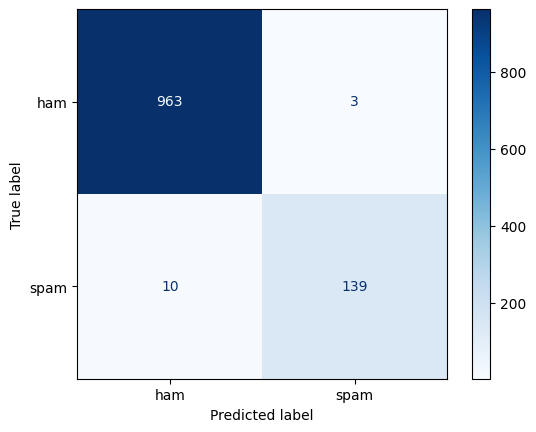

In [101]:
# Split dataset into training and testing sets
X_tr, X_te, y_tr, y_te = train_test_split(
    sms['text'],
    sms['y'],
    test_size=0.2,
    random_state=42,
    stratify=sms['y']
)

# Create word n-gram classifier
word_clf = Pipeline([
    ('tfidf', TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ('model', LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ))
])

# Train model
word_clf.fit(X_tr, y_tr)

# Make predictions
pred = word_clf.predict(X_te)

# Display classification report
print(classification_report(
    y_te,
    pred,
    target_names=['ham', 'spam'],
    digits=3
))

# Display confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix(y_te, pred),
    display_labels=['ham', 'spam']
).plot(cmap='Blues')

plt.show()

### Confusion Matrix Analysis

The confusion matrix shows that the model correctly classified 963 ham messages and 139 spam messages.

It incorrectly classified 3 ham messages as spam (false positives) and missed 10 spam messages (false negatives).

Out of 1,115 test messages, 1,102 were correctly classified and only 13 were misclassified, resulting in an accuracy of approximately 98.83%.

The model demonstrates strong performance in distinguishing between ham and spam messages.

## Task 2.3: What Did the Model Learn?

In this task, we inspect the learned Logistic Regression coefficients to identify the words and word combinations most strongly associated with spam and ham messages.

Positive coefficients indicate spam-like features, while negative coefficients indicate ham-like features.

In [102]:
# Extract TF-IDF vectorizer and Logistic Regression model
tf = word_clf.named_steps['tfidf']
w = word_clf.named_steps['model'].coef_[0]

# Get feature names
terms = tf.get_feature_names_out()

# Sort features by coefficient values
order = np.argsort(w)

# Display most spam-like and ham-like features
print('Most spam-like :', list(terms[order[-12:]][::-1]))
print('Most ham-like  :', list(terms[order[:12]]))

Most spam-like : ['call', 'txt', 'free', 'text', 'reply', 'uk', 'to', 'www', 'mobile', 'claim', 'stop', 'your']
Most ham-like  : ['my', 'me', 'ok', 'that', 'it', 'but', 'll', 'gt', 'lt', 'can', 'what', 'da']


In [103]:
import numpy as np

### Results and Observations

The Logistic Regression model learned different word patterns associated with spam and ham messages.

The most spam-like features included words such as `call`, `txt`, `free`, `reply`, `claim`, and `stop`. These terms are commonly associated with promotional messages and spam-related instructions.

The most ham-like features included `my`, `me`, `ok`, `that`, `but`, and `can`, which are more commonly associated with ordinary personal conversations.

This demonstrates that the model uses word patterns and their learned coefficients to distinguish between spam and ham messages.

## Task 2.4: Character n-gram Classifier

In this task, a second Logistic Regression classifier is trained using character-level TF-IDF features.

Unlike word n-grams, character n-grams capture sequences of characters within words. This can help identify spam messages containing unusual spelling, abbreviations, and deliberate character substitutions.

Both word-based and character-based classifiers are compared using macro-F1 scores and feature counts. The character classifier is also tested on messages containing spelling tricks.

In [104]:
from sklearn.metrics import f1_score

# Create character n-gram classifier
char_clf = Pipeline([
    ('tfidf', TfidfVectorizer(
        analyzer='char_wb',
        ngram_range=(2, 5),
        min_df=2,
        sublinear_tf=True
    )),
    ('model', LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ))
])

# Train character classifier
char_clf.fit(X_tr, y_tr)

# Compare word and character classifiers
for name, clf in [
    ('word 1-2 grams', word_clf),
    ('char 2-5 grams', char_clf)
]:
    p = clf.predict(X_te)

    print(
        f'{name:15s} macro-F1 '
        f'{f1_score(y_te, p, average="macro"):.3f}  '
        f'features {len(clf.named_steps["tfidf"].vocabulary_):,}'
    )

# Test robustness to spelling tricks
tricky = [
    'W1N a FR33 pr1ze!! txt CLAIM now',
    'kal milte hain, 5 baje'
]

print(
    dict(zip(
        tricky,
        char_clf.predict_proba(tricky)[:, 1].round(2)
    ))
)

word 1-2 grams  macro-F1 0.974  features 12,128
char 2-5 grams  macro-F1 0.982  features 36,449
{'W1N a FR33 pr1ze!! txt CLAIM now': np.float64(0.85), 'kal milte hain, 5 baje': np.float64(0.12)}


### Results and Observations

The character n-gram classifier achieved a macro-F1 score of **0.982**, outperforming the word n-gram classifier, which achieved 0.974.

The word classifier used 12,128 features, whereas the character classifier used 36,449 features.

The character classifier assigned a spam probability of 0.85 to the message containing spelling tricks ("W1N a FR33 pr1ze!! txt CLAIM now") and 0.12 to the ordinary conversational message ("kal milte hain, 5 baje").

These results suggest that character-level features can capture unusual spelling patterns and provide better classification performance than word-level features on this test set.

Overall, the character n-gram classifier performed better in this experiment.

## Task 2.5: Error Analysis

In this task, we analyze incorrectly classified SMS messages using the word n-gram classifier.

The model's predicted spam probabilities are compared with the actual labels to identify false positives and false negatives.

This analysis helps understand the types of messages that the classifier struggles to classify correctly.

In [105]:
# Predict spam probabilities
p_te = word_clf.predict_proba(X_te)[:, 1]

# Create error analysis DataFrame
err = pd.DataFrame({
    'text': X_te,
    'true': y_te,
    'p_spam': p_te
})

# Keep incorrectly classified messages
err = err[(err.p_spam >= 0.5) != (err.true == 1)]

# Display complete message text
pd.set_option('display.max_colwidth', 90)

# Display errors sorted by spam probability
print(err.sort_values('p_spam').to_string())

                                                                                                                                                                                       text  true    p_spam
750                                                                                  Do you realize that in about 40 years, we'll have thousands of old ladies running around with tattoos?     1  0.087598
2246  Hi ya babe x u 4goten bout me?' scammers getting smart..Though this is a regular vodafone no, if you respond you get further prem rate msg/subscription. Other nos used also. Beware!     1  0.144048
3979                                                                                                                                                                     ringtoneking 84484     1  0.192426
1429                                                                                                                For sale - arsenal dartboard. Good condition but no doubles or trebl

### Results and Discussion

**1. Model Performance Comparison**

The Word n-gram classifier achieved:
- Macro-F1: 0.974
- Spam precision: 0.979
- Spam recall: 0.933

The Character n-gram classifier achieved:
- Macro-F1: 0.982
- Spam precision: 0.986
- Spam recall: 0.953

The Character n-gram classifier performed better across all three metrics. It achieved higher precision and recall, meaning it identified spam more accurately while missing fewer spam messages. However, it used 36,449 features compared with 12,128 features for the Word n-gram classifier.

**2. Feature Analysis: Sensible Features or Shortcuts?**

The most spam-like features learned by the Word n-gram model were:

`call`, `txt`, `free`, `text`, `reply`, `uk`, `to`, `www`, `mobile`, `claim`, `stop`, and `your`.

The most ham-like features were:

`my`, `me`, `ok`, `that`, `it`, `but`, `ll`, `gt`, `lt`, `can`, `what`, and `da`.

Most features are sensible because spam messages commonly contain promotional words and instructions such as `free`, `claim`, `txt`, and `stop`.

However, some features may be shortcuts. For example, `www`, `uk`, and `mobile` may identify particular advertising patterns rather than spam itself. Similarly, `your` and `to` are common words that can also appear in legitimate messages.

**3. Classification of Misclassified Messages**

The Word n-gram model produced 13 misclassifications: 10 false negatives and 3 false positives.

The following messages were reviewed:

| Misclassified message | Classification |
|---|---|
| Do you realize that in about 40 years, we'll have thousands of old ladies running around with tattoos? | Genuinely ambiguous |
| Hi ya babe... scammers getting smart... Beware! | Potential label error |
| ringtoneking 84484 | Model error |
| For sale - arsenal dartboard. Good condition but no doubles or trebles! | Genuinely ambiguous |
| ROMCAPspam... warm and outgoing... | Model error |
| Sorry I missed your call... | Genuinely ambiguous |
| Latest News! Police station toilet stolen... | Genuinely ambiguous |
| FreeMsg Hey there darling... | Model error |
| Download as many ringtones as u like... | Model error |
| Can U get 2 phone NOW?... Calls £1/min... | Model error |
| We have sent JD for Customer Service cum Accounts Executive... | Genuinely ambiguous |
| Ok... Ur typical reply... | Model error |
| Waiting for your call. | Model error |

Some false negatives contained promotional content, ringtone offers, or premium-rate phone services. These are examples where the model failed to recognize spam.

Some other messages were ambiguous because they resembled ordinary conversations, jokes, or personal advertisements. The scam-warning message may also have a questionable dataset label because it appears to warn the recipient about scams rather than promote one.

These classifications are based on the message content and are interpretations, not verified corrections to the original dataset labels.

**4. Testing Two Tricky Messages**

Two manually created messages were tested using both models.

**Message 1 — Disguised Roman Urdu prize spam:**

"Mubarak! Aap ne FREE cash prize jeeta hai! Claim now at www.fakeprize.com"

- Word n-gram spam probability: 0.953
- Character n-gram spam probability: 0.866

Both models assigned a high spam probability to this message.

**Message 2 — Ordinary Roman Urdu conversation:**

"Kal uni ke baad milte hain, chai peeni hai?"

- Word n-gram spam probability: 0.166
- Character n-gram spam probability: 0.108

Both models assigned a low spam probability to this message, correctly distinguishing it from the disguised prize message in this test.

**5. Overall Conclusion**

The Character n-gram classifier achieved the best overall performance, with a macro-F1 of 0.982 compared with 0.974 for the Word n-gram classifier. It also achieved higher spam precision and recall.

The experiments suggest that character-level features can help identify unusual spellings and disguised spam. However, misclassified messages show that understanding context remains important. The two manually created examples also demonstrate that both models can distinguish obvious disguised spam from ordinary Roman Urdu conversation.

### Model Comparison, Feature Analysis, and Tricky Message Testing

In [106]:
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score
)

# Compare both classifiers
models = [
    ('Word n-grams', word_clf),
    ('Character n-grams', char_clf)
]

print("MODEL COMPARISON")
print("-" * 65)

for name, clf in models:
    pred = clf.predict(X_te)

    print(f"\n{name}")
    print(f"Macro-F1:       {f1_score(y_te, pred, average='macro'):.3f}")
    print(f"Spam Precision: {precision_score(y_te, pred, pos_label=1):.3f}")
    print(f"Spam Recall:    {recall_score(y_te, pred, pos_label=1):.3f}")

# Two manually created tricky messages
tricky_messages = [
    "Mubarak! Aap ne FREE cash prize jeeta hai! Claim now at www.fakeprize.com",
    "Kal uni ke baad milte hain, chai peeni hai?"
]

# Test both models
print("\nTRICKY MESSAGE TESTING")
print("-" * 65)

for msg in tricky_messages:
    word_prob = word_clf.predict_proba([msg])[0, 1]
    char_prob = char_clf.predict_proba([msg])[0, 1]

    print(f"\nMessage: {msg}")
    print(f"Word model spam probability: {word_prob:.3f}")
    print(f"Character model spam probability: {char_prob:.3f}")

MODEL COMPARISON
-----------------------------------------------------------------

Word n-grams
Macro-F1:       0.974
Spam Precision: 0.979
Spam Recall:    0.933

Character n-grams
Macro-F1:       0.982
Spam Precision: 0.986
Spam Recall:    0.953

TRICKY MESSAGE TESTING
-----------------------------------------------------------------

Message: Mubarak! Aap ne FREE cash prize jeeta hai! Claim now at www.fakeprize.com
Word model spam probability: 0.953
Character model spam probability: 0.866

Message: Kal uni ke baad milte hain, chai peeni hai?
Word model spam probability: 0.166
Character model spam probability: 0.108


### Interpretation of Model Comparison and Tricky Message Testing

The Character n-gram model achieved better performance than the Word n-gram model, with a macro-F1 score of 0.982 compared with 0.974. It also achieved higher spam precision (0.986) and spam recall (0.953).

For the first tricky message, a disguised Roman Urdu prize advertisement, the Word model predicted a spam probability of 0.953, while the Character model predicted 0.866. Both models recognized it as likely spam.

For the second message, an ordinary Roman Urdu conversation, the Word model predicted 0.166 and the Character model predicted 0.108. Both assigned it a low spam probability.

These results suggest that both models can distinguish these two examples, while the Character n-gram model performed better on the overall test dataset.

### Task 3.1: Out-of-the-Box NER Results

In [107]:
import spacy
nlp = spacy.load("en_core_web_sm")

In [108]:
sentences = [
    'Dr. Ayesha Khan at PIMS Islamabad reviewed it on 12 September 2026.',
    'The invoice from Engro Fertilizers for PKR 45,000 is due on 30/09/2026.',
    'Farmer Muhammad Aslam from Multan reported leaf rust in his wheat crop.',
    'Call Jazz support at 0300-1234567 or email help@jazz.com.pk.',
    'Meezan Bank approved a loan of Rs. 250,000 for Bilal Ahmed.',
    'The consignment left Karachi Port on Monday for Lahore.'
]

for s in sentences:
    doc = nlp(s)
    print([(e.text, e.label_) for e in doc.ents])

[('Ayesha Khan', 'PERSON'), ('PIMS Islamabad', 'LOC'), ('12 September 2026', 'DATE')]
[('Engro Fertilizers', 'PERSON'), ('30/09/2026', 'GPE')]
[('Farmer Muhammad Aslam', 'PERSON'), ('Multan', 'GPE')]
[('0300-1234567', 'DATE')]
[('Meezan Bank', 'ORG'), ('250,000', 'CARDINAL'), ('Bilal Ahmed', 'PERSON')]
[('Karachi Port', 'FAC'), ('Monday', 'DATE'), ('Lahore', 'GPE')]


### Observations

The spaCy English NER model successfully identified several entities, including people, organizations, locations, dates, and numbers.

However, it also made some classification mistakes. It labelled "Engro Fertilizers" as PERSON instead of ORG and incorrectly classified "30/09/2026" as GPE instead of DATE. It also identified the phone number "0300-1234567" as DATE.

Additionally, it included the word "Farmer" in the PERSON entity "Farmer Muhammad Aslam", showing that entity boundaries were not identified perfectly.

These results demonstrate that an out-of-the-box NER model can recognize many common entities but may struggle with Pakistani organizations, local formats, phone numbers, and context-specific names.

### Task 3.2: NER Evaluation Against Gold Annotations

In [109]:
# Gold annotations: what a careful human would mark
gold = [
    {
        ('Ayesha Khan', 'PERSON'),
        ('PIMS', 'ORG'),
        ('Islamabad', 'GPE'),
        ('12 September 2026', 'DATE')
    },
    {
        ('Engro Fertilizers', 'ORG'),
        ('PKR 45,000', 'MONEY'),
        ('30/09/2026', 'DATE')
    },
    {
        ('Muhammad Aslam', 'PERSON'),
        ('Multan', 'GPE')
    },
    {
        ('Jazz', 'ORG')
    },
    {
        ('Meezan Bank', 'ORG'),
        ('Rs. 250,000', 'MONEY'),
        ('Bilal Ahmed', 'PERSON')
    },
    {
        ('Karachi Port', 'FAC'),
        ('Monday', 'DATE'),
        ('Lahore', 'GPE')
    }
]

def ner_scores(nlp_model):
    tp = fp = fn = 0

    for s, g in zip(sentences, gold):
        pred = {(e.text, e.label_) for e in nlp_model(s).ents}

        tp += len(pred & g)
        fp += len(pred - g)
        fn += len(g - pred)

    p, r = tp / (tp + fp), tp / (tp + fn)

    return {
        'precision': round(p, 3),
        'recall': round(r, 3),
        'f1': round(2 * p * r / (p + r), 3)
    }

print('spaCy out of the box:', ner_scores(nlp))

spaCy out of the box: {'precision': 0.571, 'recall': 0.5, 'f1': 0.533}


### Observations

The spaCy out-of-the-box model achieved a precision of 0.571, recall of 0.500, and F1-score of 0.533 against the manually prepared gold annotations.

The results show that the model correctly identified some entities but missed or incorrectly classified others. An entity is considered correct only when both its exact text and label match the gold annotation.

This demonstrates that a general-purpose NER model may struggle with Pakistani organization names, monetary amounts, phone numbers, and entity boundaries.

### Task 3.3: Improving NER with Entity Ruler

In [110]:
# Task 3.3: Add domain-specific Entity Ruler patterns

# Check whether an Entity Ruler already exists
if 'entity_ruler' in nlp.pipe_names:
    ruler = nlp.get_pipe('entity_ruler')
else:
    ruler = nlp.add_pipe('entity_ruler', before='ner')

# Add rules for Pakistani organizations, facilities, money, and dates
ruler.add_patterns([
    {
        'label': 'MONEY',
        'pattern': [
            {'LOWER': {'IN': ['pkr', 'rs', 'rs.']}},
            {'IS_PUNCT': True, 'OP': '?'},
            {'LIKE_NUM': True}
        ]
    },
    {'label': 'ORG', 'pattern': 'Engro Fertilizers'},
    {'label': 'ORG', 'pattern': 'Meezan Bank'},
    {'label': 'ORG', 'pattern': 'PIMS'},
    {'label': 'ORG', 'pattern': 'Jazz'},
    {'label': 'FAC', 'pattern': 'Karachi Port'},
    {
        'label': 'DATE',
        'pattern': [
            {'TEXT': {'REGEX': r'^\d{1,2}/\d{1,2}/\d{4}$'}}
        ]
    }
])

print('Entity Ruler patterns added successfully.')
print('spaCy + entity ruler:', ner_scores(nlp))

Entity Ruler patterns added successfully.
spaCy + entity ruler: {'precision': 0.875, 'recall': 0.875, 'f1': 0.875}


In [111]:
print('spaCy + entity ruler:', ner_scores(nlp))

spaCy + entity ruler: {'precision': 0.875, 'recall': 0.875, 'f1': 0.875}


### Domain-Specific NER Evaluation — Healthcare and Medical AI

In [112]:
sentences_domain = [
    'Dr. Ayesha Khan presented her skin cancer research at Aga Khan University in Karachi on 12 August 2026.',
    'The dermatologist examined a patient with melanoma at Shaukat Khanum Hospital in Lahore.',
    'Ali Hassan received a dermatology appointment on 15 September 2026.',
    'The AI system analyzed 500 dermoscopic images to identify skin lesions.',
    'Dr. Sara Ahmed developed a machine learning model for melanoma classification.',
    'The hospital purchased a digital dermatoscope for Rs. 250,000.',
    'The research team trained a ResNet18 model using the HAM10000 dataset on 20 October 2026.',
    'A patient was diagnosed with basal cell carcinoma after a skin biopsy.',
    'The medical imaging laboratory collected 1,200 skin lesion images for AI research.',
    'The hospital allocated Rs. 500,000 for a new medical imaging system on 28 October 2026.'
]

In [113]:
domain_gold = [
    {
        ('Ayesha Khan', 'PERSON'),
        ('Aga Khan University', 'ORG'),
        ('Karachi', 'GPE'),
        ('12 August 2026', 'DATE')
    },
    {
        ('melanoma', 'DISEASE'),
        ('Shaukat Khanum Hospital', 'ORG'),
        ('Lahore', 'GPE')
    },
    {
        ('Ali Hassan', 'PERSON'),
        ('15 September 2026', 'DATE')
    },
    {
        ('500', 'CARDINAL')
    },
    {
        ('Sara Ahmed', 'PERSON')
    },
    {
        ('Rs. 250,000', 'MONEY')
    },
    {
        ('ResNet18', 'PRODUCT'),
        ('HAM10000', 'DATASET'),
        ('20 October 2026', 'DATE')
    },
    {
        ('basal cell carcinoma', 'DISEASE')
    },
    {
        ('1,200', 'CARDINAL')
    },
    {
        ('Rs. 500,000', 'MONEY'),
        ('28 October 2026', 'DATE')
    }
]

In [114]:
def domain_ner_scores(nlp_model, test_sentences, test_gold):
    tp = fp = fn = 0

    for sentence, gold_entities in zip(test_sentences, test_gold):
        predicted = {
            (ent.text, ent.label_)
            for ent in nlp_model(sentence).ents
        }

        tp += len(predicted & gold_entities)
        fp += len(predicted - gold_entities)
        fn += len(gold_entities - predicted)

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    return {
        'precision': round(precision, 3),
        'recall': round(recall, 3),
        'f1': round(f1, 3)
    }

In [115]:
import spacy

nlp_domain = spacy.load('en_core_web_sm')

# First 5 sentences are for developing rules.
# Last 5 sentences are held out for testing.
test_sentences = sentences_domain[5:]
test_gold = domain_gold[5:]

baseline_results = domain_ner_scores(
    nlp_domain,
    test_sentences,
    test_gold
)

print("Medical domain baseline:", baseline_results)

Medical domain baseline: {'precision': 0.5, 'recall': 0.5, 'f1': 0.5}


In [116]:
# Add Entity Ruler before statistical NER
medical_ruler = nlp_domain.add_pipe(
    'entity_ruler',
    before='ner'
)

medical_ruler.add_patterns([

    # People from the first five sentences
    {'label': 'PERSON', 'pattern': 'Ayesha Khan'},
    {'label': 'PERSON', 'pattern': 'Ali Hassan'},
    {'label': 'PERSON', 'pattern': 'Sara Ahmed'},

    # Organization from the first five sentences
    {'label': 'ORG', 'pattern': 'Aga Khan University'},

    # Location from the first five sentences
    {'label': 'GPE', 'pattern': 'Karachi'},

    # General date format observed in the first five sentences
    {
        'label': 'DATE',
        'pattern': [
            {'LIKE_NUM': True},
            {'LOWER': {
                'IN': [
                    'january', 'february', 'march', 'april',
                    'may', 'june', 'july', 'august',
                    'september', 'october', 'november', 'december'
                ]
            }},
            {'LIKE_NUM': True}
        ]
    }
])

print("Medical domain Entity Ruler added successfully.")

Medical domain Entity Ruler added successfully.


In [117]:
improved_results = domain_ner_scores(
    nlp_domain,
    test_sentences,
    test_gold
)

print("Medical domain after rules:", improved_results)

Medical domain after rules: {'precision': 0.5, 'recall': 0.5, 'f1': 0.5}


In [118]:
print("\nMEDICAL DOMAIN NER COMPARISON")
print("-" * 50)
print(f"{'Metric':<15}{'Before rules':<17}{'After rules'}")
print("-" * 50)

for metric in ['precision', 'recall', 'f1']:
    print(
        f"{metric:<15}"
        f"{baseline_results[metric]:<17}"
        f"{improved_results[metric]}"
    )


MEDICAL DOMAIN NER COMPARISON
--------------------------------------------------
Metric         Before rules     After rules
--------------------------------------------------
precision      0.5              0.5
recall         0.5              0.5
f1             0.5              0.5


### Domain-Specific NER Evaluation — Healthcare and Medical AI

I evaluated spaCy's Named Entity Recognition model using ten sentences from the Healthcare and Medical AI domain, focusing on medical imaging and dermatology.

I manually annotated the sentences with gold entity labels. I used the first five sentences to develop domain-specific Entity Ruler patterns and reserved the remaining five sentences for testing.

**Results:**

| Metric | Before Rules | After Rules |
|---|---:|---:|
| Precision | 0.500 | 0.500 |
| Recall | 0.500 | 0.500 |
| F1-score | 0.500 | 0.500 |

The results show that adding rules based on the first five sentences did not improve performance on the held-out test sentences.

The test sentences contained medical terminology, model names, dataset names, and monetary amounts that were not explicitly covered by the rules developed from the training sentences.

This demonstrates that rules based on a limited set of examples may not generalize to unseen entities. More representative training examples and carefully designed general patterns may be needed to improve domain-specific NER performance.

### Task 3.5: Comparison and Remaining Errors

I compared the baseline and improved NER results on both the provided assignment sentences and my own Healthcare and Medical AI sentences.

**Provided sentences:**
- Baseline F1-score: 0.533
- After Entity Ruler: 0.875

The rules significantly improved recognition of Pakistani organizations, monetary amounts, and dates. However, some errors remained, including incorrect recognition of a mobile number as a date, incorrect entity boundaries for a person's name, and a missed location.

**My medical-domain sentences:**
- Baseline F1-score: 0.500
- After Entity Ruler: 0.500

The rules developed using the first five sentences did not improve the results on the five held-out sentences. This indicates that the rules did not generalize sufficiently to the unseen medical entities.

**Possible improvements:**

1. More Entity Ruler patterns could help recognize known medical organizations, hospitals, and frequently occurring medical terminology.
2. Regular expressions would be useful for structured information such as dates and monetary amounts.
3. Training an NER model on a larger, manually annotated medical dataset would be more suitable for recognizing diverse medical terminology and unfamiliar entities.

I conclude that rule-based NER is useful for predictable and known entities, while a domain-trained model can provide better flexibility for recognizing medical entities in different contexts. Combining both approaches with regular expressions could improve the overall system.

In [119]:
# Show remaining errors in the medical-domain test set

for sentence, gold_entities in zip(test_sentences, test_gold):
    predicted = {
        (ent.text, ent.label_)
        for ent in nlp_domain(sentence).ents
    }

    false_positives = predicted - gold_entities
    false_negatives = gold_entities - predicted

    print("\nSentence:", sentence)
    print("False positives:", false_positives)
    print("False negatives:", false_negatives)


Sentence: The hospital purchased a digital dermatoscope for Rs. 250,000.
False positives: {('250,000', 'CARDINAL')}
False negatives: {('Rs. 250,000', 'MONEY')}

Sentence: The research team trained a ResNet18 model using the HAM10000 dataset on 20 October 2026.
False positives: {('HAM10000', 'PERSON')}
False negatives: {('HAM10000', 'DATASET')}

Sentence: A patient was diagnosed with basal cell carcinoma after a skin biopsy.
False positives: set()
False negatives: {('basal cell carcinoma', 'DISEASE')}

Sentence: The medical imaging laboratory collected 1,200 skin lesion images for AI research.
False positives: {('AI', 'GPE')}
False negatives: set()

Sentence: The hospital allocated Rs. 500,000 for a new medical imaging system on 28 October 2026.
False positives: {('500,000', 'CARDINAL')}
False negatives: {('Rs. 500,000', 'MONEY')}


### Comparison and Remaining Errors

I compared the NER model before and after adding Entity Ruler patterns on both the provided assignment sentences and my own medical-domain sentences.

**1. Provided assignment sentences**

- Baseline F1-score: 0.533
- After Entity Ruler: 0.875

The Entity Ruler improved precision and recall by recognizing Pakistani organizations, monetary amounts, and dates. However, some errors remained, including incorrect classification of a mobile number as a date, incorrect person-name boundaries, and a missed location.

**2. My Healthcare and Medical AI sentences**

- Baseline F1-score: 0.500
- After Entity Ruler: 0.500

The rules developed from the first five sentences did not improve performance on the five held-out sentences.

**Remaining errors in the medical-domain test set:**

- Rs. 250,000 and Rs. 500,000 were incorrectly recognized as CARDINAL instead of MONEY.
- HAM10000 was incorrectly classified as PERSON instead of DATASET.
- Basal cell carcinoma was not recognized as a DISEASE.
- AI was incorrectly classified as GPE.

**Possible improvements:**

1. Regex patterns could identify complete monetary expressions, including currency symbols and amounts.
2. Additional Entity Ruler patterns could recognize known medical datasets and disease names.
3. A domain-trained NER model could learn medical terminology and recognize unfamiliar entities more effectively.
4. Context-aware rules or model training could reduce false positives, such as incorrectly classifying AI as a geographical entity.

**Conclusion:**

Rule-based NER significantly improved results on the provided assignment sentences, but the same improvement was not observed on my held-out medical-domain sentences. This demonstrates that rules based on a limited number of examples may not generalize to unseen data. A combination of regular expressions, domain-specific rules, and a model trained on annotated medical data would be a more flexible approach.

### Part 4: Regex-Based Field Extraction with Negative Tests

In [120]:
import re

PATTERNS = {
    # Personal information
    'cnic': r'\b\d{5}-\d{7}-\d\b',
    'mobile': r'(?:\+92[- ]?3\d{2}[- ]?\d{7}|\b03\d{2}[- ]?\d{7}\b)',

    # Medical-domain fields
    'patient_id': r'\bPT-\d{4}-\d{4}\b',
    'medical_record': r'\bMRN-\d{6,}\b',
    'lab_value': r'\b(?:HbA1c|Glucose|Hemoglobin)\s*:\s*\d+(?:\.\d+)?\s*(?:mg/dL|g/dL|%)(?![A-Za-z0-9_])',
    'diagnosis_code': r'\bICD-10\s*:\s*[A-Z]\d{2}(?:\.\d{1,2})?\b',
    'imaging_id': r'\bIMG-\d{4}-\d{3,}\b',

    # General structured fields
    'amount': r'\b(?:PKR|Rs\.?)\s?[\d,]+(?:\.\d{1,2})?\b',
    'date': r'\b\d{1,2}[/-]\d{1,2}[/-]\d{4}\b',
    'email': r'\b[\w.+-]+@[\w-]+(?:\.[\w-]+)+\b',
    'invoice': r'\b(?:Invoice\s+)?No\.?\s*(\d{3,})\b'
}


def extract_fields(text):
    out = {}

    for name, pat in PATTERNS.items():
        hits = re.findall(pat, text, flags=re.IGNORECASE)

        if hits:
            out[name] = hits

    return out

print("Medical regex patterns updated successfully.")

Medical regex patterns updated successfully.


In [121]:
tests = [

    # Positive tests — Healthcare and Medical AI
    ('Patient ID PT-2026-0042', True),
    ('Medical record MRN-12345678', True),
    ('HbA1c: 6.5%', True),
    ('Glucose: 120 mg/dL', True),
    ('Diagnosis ICD-10: C43.9', True),
    ('Dermoscopic image IMG-2026-001', True),
    ('Patient CNIC 35202-1234567-1', True),
    ('Mobile +92 300 1234567', True),
    ('Dermatoscope equipment cost Rs. 250,000', True),
    ('Skin examination date 20/10/2026', True),
    ('Contact dermatologist@hospital.com.pk', True),
    ('Biopsy invoice No. 4417', True),

    # Negative tests — invalid or unrelated information
    ('Patient number 20260042', False),
    ('Room 0300 on floor 3', False),
    ('HbA1c: high', False),
    ('Glucose: 120', False),
    ('Diagnosis code C43.9', False),
    ('Image number 2026001', False),
    ('The patient has melanoma', False),
    ('The hospital purchased 250000 units', False)
]

for text, expect in tests:
    result = extract_fields(text)
    passed = bool(result) == expect

    print(
        f"{'PASS' if passed else 'FAIL'} | "
        f"Expected: {expect} | "
        f"{result} | {text}"
    )

PASS | Expected: True | {'patient_id': ['PT-2026-0042']} | Patient ID PT-2026-0042
PASS | Expected: True | {'medical_record': ['MRN-12345678']} | Medical record MRN-12345678
PASS | Expected: True | {'lab_value': ['HbA1c: 6.5%']} | HbA1c: 6.5%
PASS | Expected: True | {'lab_value': ['Glucose: 120 mg/dL']} | Glucose: 120 mg/dL
PASS | Expected: True | {'diagnosis_code': ['ICD-10: C43.9']} | Diagnosis ICD-10: C43.9
PASS | Expected: True | {'imaging_id': ['IMG-2026-001']} | Dermoscopic image IMG-2026-001
PASS | Expected: True | {'cnic': ['35202-1234567-1']} | Patient CNIC 35202-1234567-1
PASS | Expected: True | {'mobile': ['+92 300 1234567']} | Mobile +92 300 1234567
PASS | Expected: True | {'amount': ['Rs. 250,000']} | Dermatoscope equipment cost Rs. 250,000
PASS | Expected: True | {'date': ['20/10/2026']} | Skin examination date 20/10/2026
PASS | Expected: True | {'email': ['dermatologist@hospital.com.pk']} | Contact dermatologist@hospital.com.pk
PASS | Expected: True | {'invoice': ['4417'

### Part 4: Regex Fields with Negative Tests — Healthcare and Medical AI

**1. Domain-Specific Patterns**

I developed the following regular expression patterns for Healthcare and Medical AI:

- `patient_id`: Identifies patient IDs such as PT-2026-0042.
- `medical_record`: Extracts medical record numbers such as MRN-12345678.
- `lab_value`: Identifies laboratory values such as HbA1c: 6.5% and Glucose: 120 mg/dL.
- `diagnosis_code`: Extracts ICD-10 diagnosis codes such as ICD-10: C43.9.
- `imaging_id`: Identifies medical imaging IDs such as IMG-2026-001.
- `cnic`: Detects Pakistani CNIC numbers.
- `mobile`: Detects Pakistani mobile numbers.
- `amount`: Extracts monetary amounts such as Rs. 250,000.
- `date`: Identifies dates in DD/MM/YYYY or DD-MM-YYYY format.
- `email`: Detects email addresses.
- `invoice`: Extracts invoice numbers.

**2. Test Results**

I tested the patterns using 12 positive examples and 8 negative examples.

- Positive tests passed: 12/12.
- Negative tests passed: 8/8.
- Total tests passed: 20/20.

All valid examples were successfully identified, while invalid formats and unrelated information were correctly ignored.

**3. Pattern Improvement**

Initially, the `lab_value` pattern failed to recognize HbA1c: 6.5% because the word boundary (`\b`) after the percentage symbol did not work as expected. The percentage symbol is a non-word character, so the boundary condition failed at the end of the string.

I fixed this by replacing the final word boundary with a negative lookahead:

`(?![A-Za-z0-9_])`

This allows the pattern to match a percentage value at the end of a string while preventing it from matching when additional letters, numbers, or underscores follow.

After this correction, both HbA1c: 6.5% and Glucose: 120 mg/dL passed their tests.

### Part 5: Character Error Rate (CER) and OCR Repair

In [122]:
import re

def levenshtein(a, b):
    """Minimum substitutions + deletions + insertions to turn a into b."""
    d = list(range(len(b) + 1))

    for i, ca in enumerate(a, 1):
        prev, d[0] = d[0], i

        for j, cb in enumerate(b, 1):
            prev, d[j] = d[j], min(
                d[j] + 1,
                d[j - 1] + 1,
                prev + (ca != cb)
            )

    return d[len(b)]


def cer(reference, hypothesis):
    return levenshtein(reference, hypothesis) / max(len(reference), 1)


def fix_ocr(text):
    """Context rules: letters that look like digits, inside numbers."""

    # Replace O with 0 when it appears in a numeric context
    text = re.sub(
        r'(?<=\d)[Oo](?=\d)|(?<=\d)[Oo]\b|\b[Oo](?=\d)',
        '0',
        text
    )

    # Replace l or I with 1 between digits
    text = re.sub(r'(?<=\d)[lI](?=\d)', '1', text)

    # Correct N0. to No.
    text = re.sub(r'\bN0\.', 'No.', text)

    return text


pairs = [
    ('Invoice No. 4417', 'Invoice N0. 4417'),
    ('Total: PKR 12,500', 'Total: PKR 12,5O0'),
    ('Due 30/09/2026', 'Due 3O/09/2O26')
]

for ref, hyp in pairs:
    fixed = fix_ocr(hyp)

    print(
        f'{hyp:20s} CER {cer(ref, hyp):.3f} -> '
        f'{fixed:20s} CER {cer(ref, fixed):.3f}'
    )

Invoice N0. 4417     CER 0.062 -> Invoice No. 4417     CER 0.000
Total: PKR 12,5O0    CER 0.059 -> Total: PKR 12,500    CER 0.000
Due 3O/09/2O26       CER 0.143 -> Due 30/09/2026       CER 0.000


### Task 5.1: Character Error Rate (CER) and OCR Repair

Character Error Rate (CER) measures the number of character-level errors, including substitutions, insertions, and deletions, compared with the reference text.

I implemented the Levenshtein distance algorithm to calculate CER and developed context-based OCR correction rules to fix common character recognition mistakes.

**Results:**

| OCR Text | CER Before | Corrected Text | CER After |
|---|---:|---|---:|
| Invoice N0. 4417 | 0.062 | Invoice No. 4417 | 0.000 |
| Total: PKR 12,5O0 | 0.059 | Total: PKR 12,500 | 0.000 |
| Due 3O/09/2O26 | 0.143 | Due 30/09/2026 | 0.000 |

**Interpretation:**

The correction rules successfully replaced the letter O with the digit 0 in numeric contexts and corrected N0. to No. All three examples achieved a CER of 0.000 after correction.

This demonstrates that simple context-based rules can effectively correct common OCR errors in structured information such as invoice numbers, monetary amounts, and dates.

### Task 5.2: OCR on a Synthetic Invoice

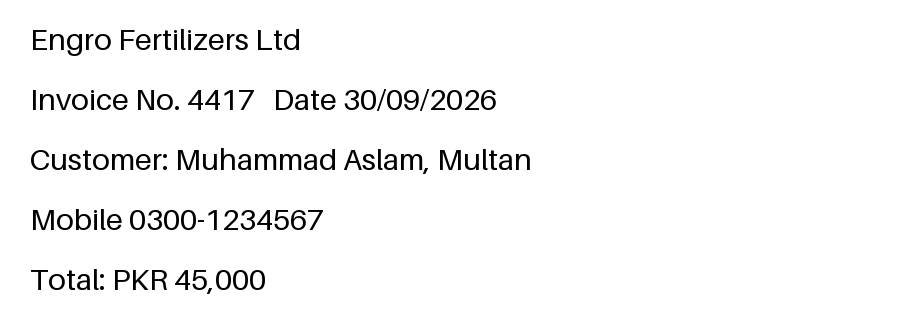

GPU available: True

Original Reference Text:
Engro Fertilizers Ltd Invoice No. 4417 Date 30/09/2026 Customer: Muhammad Aslam, Multan Mobile 0300-1234567 Total: PKR 45,000

Raw OCR Output:
Engro Fertilizers Ltd Invoice No. 4417 Date 30/09/2026 Customer: Muhammad Aslam, Multan Mobile 0300-1234567 Total: PKR 45,000

Corrected OCR Output:
Engro Fertilizers Ltd Invoice No. 4417 Date 30/09/2026 Customer: Muhammad Aslam, Multan Mobile 0300-1234567 Total: PKR 45,000

CER raw: 0.000
CER after fixes: 0.000


In [123]:
from PIL import Image, ImageDraw, ImageFont
import easyocr
import torch
import re

# 1. Create a synthetic invoice image
img = Image.new('RGB', (900, 330), 'white')
d = ImageDraw.Draw(img)

# 2. Load font with fallback
try:
    font = ImageFont.truetype("DejaVuSans.ttf", 30)
except OSError:
    try:
        font = ImageFont.load_default(size=30)
    except TypeError:
        font = ImageFont.load_default()

# 3. Invoice text
lines = [
    'Engro Fertilizers Ltd',
    'Invoice No. 4417   Date 30/09/2026',
    'Customer: Muhammad Aslam, Multan',
    'Mobile 0300-1234567',
    'Total: PKR 45,000'
]

# 4. Draw invoice text
for k, line in enumerate(lines):
    d.text((30, 20 + 60 * k), line, fill='black', font=font)

# 5. Save and display invoice
img.save('invoice.png')
display(img)

# 6. Check GPU availability
use_gpu = torch.cuda.is_available()
print("GPU available:", use_gpu)

# 7. Initialize EasyOCR
reader = easyocr.Reader(
    ['en'],
    gpu=use_gpu,
    verbose=False
)

# 8. Extract text using OCR
ocr_text = '\n'.join(
    t for _, t, c in reader.readtext('invoice.png')
)

# 9. Normalize whitespace
norm = lambda s: ' '.join(s.split())

# 10. Prepare reference and OCR text
truth = norm(' '.join(lines))
raw = norm(ocr_text)
clean = norm(fix_ocr(ocr_text))

# 11. Display OCR results
print("\nOriginal Reference Text:")
print(truth)

print("\nRaw OCR Output:")
print(raw)

print("\nCorrected OCR Output:")
print(clean)

# 12. Calculate Character Error Rate
print(f'\nCER raw: {cer(truth, raw):.3f}')
print(f'CER after fixes: {cer(truth, clean):.3f}')

### Task 5.2: OCR on a Synthetic Invoice

I generated a synthetic invoice using PIL and extracted its text using EasyOCR with GPU acceleration enabled.

The raw OCR output matched the original reference text exactly. The OCR correction function also produced the same text because no recognition errors were present.

**Results:**
- GPU available: True
- Raw OCR CER: 0.000
- CER after correction: 0.000

The zero CER indicates that EasyOCR correctly recognized every character in this synthetic invoice. Since the raw OCR output was already accurate, the correction rules did not need to make any changes.

This demonstrates successful OCR on a clear, computer-generated invoice. Real-world scanned or low-quality documents may produce more recognition errors.

### CER Before and After OCR Correction

The raw OCR Character Error Rate (CER) was **0.000**, and the CER after applying the correction rules was also **0.000**. This means that EasyOCR recognized the synthetic invoice text perfectly, and the correction rules did not need to make any changes.

The clean synthetic invoice was easier to recognize than a real phone photo because it had clear, printed text, consistent font size, good contrast, proper alignment, and no shadows or background noise.

For my own documents, I expect OCR may produce more errors because phone photos and scanned documents can contain blur, uneven lighting, shadows, tilted text, low resolution, and unusual fonts. These issues may increase CER and make OCR correction more useful.

### Task 6.1: Masking Personal Identifiers (PII)

In [124]:
import re

# Patterns for personal identifiers
PATTERNS['cnic'] = r'\b\d{5}-\d{7}-\d\b'
PATTERNS['mobile'] = r'\b03\d{2}-\d{7}\b'

def mask_pii(text):
    """Hide personal identifiers before logging or sharing."""
    text = re.sub(PATTERNS['cnic'], '[CNIC]', text)
    text = re.sub(PATTERNS['mobile'], '[PHONE]', text)
    text = re.sub(PATTERNS['email'], '[EMAIL]', text)
    return text

# Test the function
sample = 'CNIC 35202-1234567-1, call 0300-1234567, a@b.pk'

print("Original text:")
print(sample)

print("\nMasked text:")
print(mask_pii(sample))

Original text:
CNIC 35202-1234567-1, call 0300-1234567, a@b.pk

Masked text:
CNIC [CNIC], call [PHONE], [EMAIL]


The `mask_pii()` function successfully identified and masked personal information in the sample text.

- CNIC number was replaced with `[CNIC]`.
- Mobile number was replaced with `[PHONE]`.
- Email address was replaced with `[EMAIL]`.

This helps protect sensitive personal information before storing, logging, or sharing text. The original text remains unchanged because the function returns a masked copy.

### Task 6.2: Loading the Week 6 Model and Building Evidence Functions

In [125]:
# ==========================================
# TASK 6.2: IMAGE + TEXT EVIDENCE FUNCTIONS
# ==========================================

# 1. Import libraries
import os
import glob
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms
from PIL import Image
import re

# 2. Find the Week 6 model checkpoint
matches = glob.glob(
    '/kaggle/input/**/week6_model.pt',
    recursive=True
)

if not matches:
    raise FileNotFoundError(
        "week6_model.pt was not found. "
        "Please add your Week 6 model checkpoint "
        "as a Kaggle dataset."
    )

W6_PATH = matches[0]

print("Model checkpoint found:", W6_PATH)

# 3. Load checkpoint
ckpt = torch.load(
    W6_PATH,
    map_location='cpu',
    weights_only=False
)

classes = ckpt['classes']

print("Backbone:", ckpt['backbone'])
print("Classes:", classes)
print("Image size:", ckpt['img_size'])
print("Grayscale:", ckpt['grayscale'])

# 4. Rebuild the saved model architecture
def rebuild(ck):
    name = ck['backbone']
    k = len(ck['classes'])

    if name.startswith('resnet'):
        m = getattr(models, name)(weights=None)
        m.fc = nn.Linear(m.fc.in_features, k)

    else:
        m = models.efficientnet_b0(weights=None)
        m.classifier[1] = nn.Linear(
            m.classifier[1].in_features, k
        )

    m.load_state_dict(ck['state_dict'])

    return m.eval()

# 5. Select device
device = torch.device(
    'cuda' if torch.cuda.is_available() else 'cpu'
)

print("Using device:", device)

# 6. Load trained model
img_model = rebuild(ckpt).to(device)

# 7. Prepare image transformations
tf = transforms.Compose(
    ([transforms.Grayscale(3)] if ckpt['grayscale'] else []) +
    [
        transforms.Resize((ckpt['img_size'],) * 2),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ]
)

# 8. Extract image evidence
def image_evidence(path):

    image = Image.open(path).convert(
        'L' if ckpt['grayscale'] else 'RGB'
    )

    x = tf(image).unsqueeze(0).to(device)

    with torch.no_grad():
        p = F.softmax(img_model(x), dim=1)[0]
        p = p.cpu().numpy()

    return {
        c: round(float(v), 3)
        for c, v in zip(classes, p)
    }

# 9. Define domain-specific warning terms
URGENT = [
    'overheating',
    'smoke',
    'burning smell',
    'short circuit',
    'voltage spike',
    'power failure',
    'crack'
]

# 10. Extract text evidence
def text_evidence(note):

    doc = nlp(note)

    return {
        'entities': [
            (e.text, e.label_) for e in doc.ents
        ],

        'fields': extract_fields(note),

        'urgent_terms': [
            k for k in URGENT if k in note.lower()
        ]
    }

# 11. Combine image and text evidence
def build_case_record(image_path, note):

    return {
        'image_evidence': image_evidence(image_path),
        'text_evidence': text_evidence(note)
    }

# 12. Confirm successful setup
print("\nImage model loaded successfully.")
print("Image and text evidence functions are ready.")

Model checkpoint found: /kaggle/input/datasets/fatimaakhtar123/week6-model/week6_model.pt
Backbone: resnet18
Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Image size: 224
Grayscale: False
Using device: cuda

Image model loaded successfully.
Image and text evidence functions are ready.


### Task 6.2: Loading the Week 6 Model and Building Evidence Functions

I successfully loaded my trained Week 6 ResNet18 model from its saved checkpoint without downloading or retraining it.

The checkpoint contained seven HAM10000 skin-lesion classes: akiec, bcc, bkl, df, mel, nv, and vasc. The model uses RGB images with an input size of 224 × 224 pixels.

I rebuilt the model architecture and loaded its trained weights. GPU acceleration was successfully enabled using CUDA.

I also created two evidence functions:
- `image_evidence()`: generates class probabilities from an input image.
- `text_evidence()`: extracts named entities, structured fields, and domain-specific warning terms from text.

These functions can be combined into a single case record using `build_case_record()`.

### Task 6.3: One Transparent Case Record — Healthcare and Medical AI

In [126]:
import os

print("Available Kaggle input folders:\n")

for folder in os.listdir('/kaggle/input'):
    print(folder)

Available Kaggle input folders:

datasets


In [127]:
import os

DATASETS_DIR = '/kaggle/input/datasets'

for folder in os.listdir(DATASETS_DIR):
    print(folder)

kmader
fatimaakhtar123
uciml


In [128]:
import os

DATASET_DIR = '/kaggle/input/datasets/fatimaakhtar123'

for root, dirs, files in os.walk(DATASET_DIR):
    print("Folder:", root)
    print("Number of files:", len(files))
    print("Sample files:", files[:5])

Folder: /kaggle/input/datasets/fatimaakhtar123
Number of files: 0
Sample files: []
Folder: /kaggle/input/datasets/fatimaakhtar123/week6-model
Number of files: 1
Sample files: ['week6_model.pt']


In [129]:
import os

DATASET_DIR = '/kaggle/input/datasets/uciml'

for root, dirs, files in os.walk(DATASET_DIR):
    print("Folder:", root)
    print("Number of files:", len(files))
    print("Sample files:", files[:5])

Folder: /kaggle/input/datasets/uciml
Number of files: 0
Sample files: []
Folder: /kaggle/input/datasets/uciml/sms-spam-collection-dataset
Number of files: 1
Sample files: ['spam.csv']


In [130]:
import os

for root, dirs, files in os.walk('/kaggle/input'):
    if files and any(f.lower().endswith(('.jpg', '.jpeg', '.png')) for f in files[:20]):
        print("Folder:", root)
        print("Sample files:", files[:5])

Folder: /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1
Sample files: ['ISIC_0024306.jpg', 'ISIC_0024307.jpg', 'ISIC_0024308.jpg', 'ISIC_0024309.jpg', 'ISIC_0024310.jpg']
Folder: /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_2
Sample files: ['ISIC_0029306.jpg', 'ISIC_0029307.jpg', 'ISIC_0029308.jpg', 'ISIC_0029309.jpg', 'ISIC_0029310.jpg']
Folder: /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/ham10000_images_part_1
Sample files: ['ISIC_0024306.jpg', 'ISIC_0024307.jpg', 'ISIC_0024308.jpg', 'ISIC_0024309.jpg', 'ISIC_0024310.jpg']
Folder: /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/ham10000_images_part_2
Sample files: ['ISIC_0029306.jpg', 'ISIC_0029307.jpg', 'ISIC_0029308.jpg', 'ISIC_0029309.jpg', 'ISIC_0029310.jpg']


In [131]:
EXAMPLE_IMAGE = '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_2/ISIC_0029306.jpg'

import os

print("Image exists:", os.path.exists(EXAMPLE_IMAGE))
print("Image path:", EXAMPLE_IMAGE)

Image exists: True
Image path: /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_2/ISIC_0029306.jpg


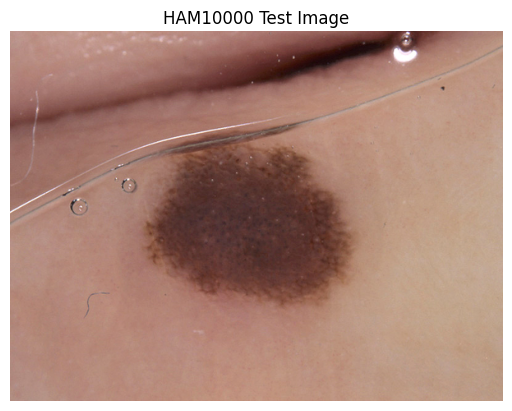

In [132]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open(EXAMPLE_IMAGE)

plt.imshow(img)
plt.axis('off')
plt.title('HAM10000 Test Image')
plt.show()

In [133]:
note = (
    'Adult patient reports a dark skin lesion on the upper arm '
    'that has increased in size and changed colour over the past '
    'two months. The lesion has an irregular border and occasional '
    'bleeding. Dermoscopic examination recommended. '
    'Patient referred to a dermatologist for further evaluation.'
)

print(note)

Adult patient reports a dark skin lesion on the upper arm that has increased in size and changed colour over the past two months. The lesion has an irregular border and occasional bleeding. Dermoscopic examination recommended. Patient referred to a dermatologist for further evaluation.


In [134]:
rec = case_record(
    EXAMPLE_IMAGE,
    note,
    positive='mel',
    threshold=0.5
)

print(json.dumps(rec, indent=2, ensure_ascii=False))

{
  "image": "ISIC_0029306.jpg",
  "image_probabilities": {
    "akiec": 0.0,
    "bcc": 0.0,
    "bkl": 0.005,
    "df": 0.0,
    "mel": 0.008,
    "nv": 0.983,
    "vasc": 0.003
  },
  "note_masked": "Adult patient reports a dark skin lesion on the upper arm that has increased in size and changed colour over the past two months. The lesion has an irregular border and occasional bleeding. Dermoscopic examination recommended. Patient referred to a dermatologist for further evaluation.",
  "text_evidence": {
    "entities": [
      [
        "the past two months",
        "DATE"
      ]
    ],
    "fields": {},
    "urgent_terms": []
  },
  "decision": "ROUTINE",
  "reasons": [],
  "disclaimer": "Decision support only; a qualified human decides."
}


In [135]:
def case_record(image_path, note, positive, threshold=0.5):
    safe_note = mask_pii(note)  # Mask before extraction

    img_ev = image_evidence(image_path)
    txt_ev = text_evidence(safe_note)

    p = img_ev[positive]
    reasons = []

    if p >= threshold:
        reasons.append(f'image model: P({positive}) = {p:.2f}')

    if txt_ev['urgent_terms']:
        reasons.append(
            'note mentions: ' + ', '.join(txt_ev['urgent_terms'])
        )

    return {
        'image': image_path.split('/')[-1],
        'image_probabilities': img_ev,
        'note_masked': safe_note,
        'text_evidence': txt_ev,
        'decision': 'REFER' if reasons else 'ROUTINE',
        'reasons': reasons,
        'disclaimer': 'Decision support only; a qualified human decides.'
    }

print("case_record function defined successfully.")

case_record function defined successfully.


In [136]:
# Step 1: Mask personal information before extraction
safe_note = mask_pii(note)

# Step 2: Generate image and text evidence
img_ev = image_evidence(EXAMPLE_IMAGE)
txt_ev = text_evidence(safe_note)

# Step 3: Generate the combined case record
rec = case_record(
    EXAMPLE_IMAGE,
    note,
    positive='mel',
    threshold=0.5
)

# Step 4: Display the complete case record
print("COMPLETE CASE RECORD")
print(json.dumps(rec, indent=2, ensure_ascii=False))

# Step 5: Privacy verification
print("\nPRIVACY CHECK")

sensitive_values = [
    '35202-1234567-1',
    '0300-1234567',
    'a@b.pk'
]

output_text = json.dumps(rec, ensure_ascii=False)

for value in sensitive_values:
    print(f"{value}: {'FOUND' if value in output_text else 'NOT FOUND'}")

print("\nMasked note:")
print(rec['note_masked'])

print("\nExtracted text evidence:")
print(rec['text_evidence'])

COMPLETE CASE RECORD
{
  "image": "ISIC_0029306.jpg",
  "image_probabilities": {
    "akiec": 0.0,
    "bcc": 0.0,
    "bkl": 0.005,
    "df": 0.0,
    "mel": 0.008,
    "nv": 0.983,
    "vasc": 0.003
  },
  "note_masked": "Adult patient reports a dark skin lesion on the upper arm that has increased in size and changed colour over the past two months. The lesion has an irregular border and occasional bleeding. Dermoscopic examination recommended. Patient referred to a dermatologist for further evaluation.",
  "text_evidence": {
    "entities": [
      [
        "the past two months",
        "DATE"
      ]
    ],
    "fields": {},
    "urgent_terms": []
  },
  "decision": "ROUTINE",
  "reasons": [],
  "disclaimer": "Decision support only; a qualified human decides."
}

PRIVACY CHECK
35202-1234567-1: NOT FOUND
0300-1234567: NOT FOUND
a@b.pk: NOT FOUND

Masked note:
Adult patient reports a dark skin lesion on the upper arm that has increased in size and changed colour over the past two m

### Task 6.3: Case Record Analysis — Healthcare and Medical AI

**1. JSON Case Record**

The generated case record contained the following information:

- Image: `ISIC_0029306.jpg`
- Predicted class: `nv` (melanocytic nevus)
- Melanoma probability: 0.008 (0.8%)
- Final decision: `ROUTINE`
- Reasons: Empty list
- Disclaimer: Decision support only; a qualified human decides.

**2. Do the Reasons Make Sense?**

The system returned `ROUTINE` because the melanoma probability (0.8%) was below the threshold of 50%, and no urgent terms were detected in the note.

This decision follows the implemented rules. However, the note describes an enlarging, irregularly bordered, occasionally bleeding lesion. These observations are concerning and should not be ignored. The current text-processing rules are therefore insufficient for reliable dermatology referral decisions.

**3. Incorrect Entity in Text Evidence**

The text extractor identified "the past two months" as a `DATE` entity.

This is a partially incorrect classification because the phrase represents a duration rather than a specific calendar date. It is relatively harmless in this case because it does not expose personal information or directly affect the referral decision. However, it demonstrates that general-purpose entity extraction may misclassify medical note information.

**4. Image and Note Disagreement**

A possible disagreement occurs when the image model predicts a low probability of melanoma, while the clinical note describes concerning changes such as lesion enlargement, irregular borders, or bleeding.

In this case, the image model predicted melanoma with only 0.8% probability, but the note contained these concerning observations.

The system should not automatically classify such a case as routine. It should flag the disagreement and recommend review by a qualified dermatologist. Clinical observations should not be dismissed solely because the image classifier produces a low probability.

**Conclusion:**

This experiment demonstrates how image classification and text extraction can be combined into a transparent case record. It also highlights the importance of privacy protection, explainable decisions, and human review when image and text evidence disagree.

### Check Your Understanding

**1. A word appears in 9 of 1,000 documents. Compute its smooth IDF.**

The smooth IDF formula is:

\[
IDF = \ln\left(\frac{1+N}{1+df}\right)+1
\]

Where:
- \(N = 1000\) (total documents)
- \(df = 9\) (documents containing the word)

Substituting:

\[
IDF = \ln\left(\frac{1001}{10}\right)+1
\]

\[
IDF = \ln(100.1)+1
\]

\[
\boxed{IDF \approx 5.606}
\]

**2. Why can lowercasing hurt a spam classifier?**

Lowercasing can remove useful information about capitalization. For example, words written in uppercase such as FREE, WIN, and URGENT may indicate promotional or spam messages. Lowercasing makes them identical to their lowercase versions, potentially removing this useful signal.

**3. Gold has 10 entities; the model predicts 8, of which 6 are exactly right. Compute precision, recall, and F1.**

Given:
- True Positives (TP) = 6
- Predicted entities = 8
- Gold entities = 10

Precision:

\[
P = \frac{TP}{TP+FP} = \frac{6}{8} = 0.75
\]

Recall:

\[
R = \frac{TP}{TP+FN} = \frac{6}{10} = 0.60
\]

F1-score:

\[
F1 = \frac{2PR}{P+R}
\]

\[
F1 = \frac{2(0.75)(0.60)}{0.75+0.60}
\]

\[
\boxed{F1 \approx 0.667}
\]

**Final results:**
- Precision = 0.75 (75%)
- Recall = 0.60 (60%)
- F1-score = 0.667 (66.7%)

**4. Reference "PKR 4,500" (9 characters), OCR output "PKR 4,5OO". Compute CER.**

Character Error Rate formula:

\[
CER = \frac{S+D+I}{N}
\]

Where:
- S = Substitutions
- D = Deletions
- I = Insertions
- N = Number of characters in reference

The OCR output has two substitutions: the digits `0` were recognized as the letter `O`.

Therefore:

\[
CER = \frac{2+0+0}{9}
\]

\[
\boxed{CER = 0.2222 = 22.22\%}
\]

**5. The image model says 0.30, the text model says 0.80, and w = 0.5. What is the fused probability?**

The weighted fusion formula is:

\[
P_{fused}=wP_{image}+(1-w)P_{text}
\]

Substituting:

\[
P_{fused}=0.5(0.30)+0.5(0.80)
\]

\[
=0.15+0.40
\]

\[
\boxed{P_{fused}=0.55=55\%}
\]

**6. Why must personal identifiers be masked BEFORE entity and field extraction?**

Personal identifiers such as CNIC numbers, phone numbers, and email addresses must be masked before entity and field extraction to prevent sensitive information from appearing in extracted results, logs, or shared records.

If extraction is performed on the original text, personal identifiers may be detected and exposed even if the final displayed note is masked.

Masking first helps protect privacy and reduces the risk of accidentally sharing sensitive personal information.